# Stuck-bayes: which parts does it need?

`stuck-bayes` is the best teacher family so far in the costly condition (agency 0, so shown moves aren't learned
from, with skipped update steps; see `rush_hour_sweep.ipynb`). It has two parts:

- **When:** a gate. It stays out until the student has made `patience` x the puzzle's optimal length moves of its own
  without getting closer to the goal than ever before.
- **How much:** a Bayesian model of the student. Once the gate is open, it shows the optimal move whenever the model
  gives the student less than `theta` chance of solving alone from here. It stops when the chance is back, steps
  straight back in if the student slides, and the gate closes at the student's next new closest approach.

This notebook strips it down, one component at a time, toward the most parsimonious teacher that keeps its learning.
All runs are added to the sweep's agency-0 run (`teach_shortcut_agency0`), so every student is the same across
teachers and comparisons are paired by student.

**First comparison: does the model's calibration matter?** `stuck-bayes` uses the calibrated model (bayes2's: a
move's chance of being optimal depends on its distance to the goal *and* from the puzzle's start, evidence kept for
1,000 puzzles). `stuck-bayes1` uses the original one (bayes's: distance to the goal only, evidence kept for 300
puzzles, too optimistic about long puzzles). As plain Bayesian teachers the miscalibrated original taught better
(bayes 3% beat bayes2 4.5% by 0.14) - it stepped in later. With the stuck gate fixing the timing for both, is the
calibration still worth anything?

`stuck-bayes1 0.25` matches `stuck-bayes 0.3`'s spend in a mini test (2 students x 80 puzzles: 4.4% against 4.5%).
If the two tie, the next step is the full spectrum of help (a theta sweep for both) before dropping the calibration.

In [1]:
import sys
sys.path.append("../scripts")
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import run_queue as rq
import session_experiment as se
import teach_experiment as te

OUT = se.OUT
FIGURES = "../visualization"
RUN = "teach_shortcut_agency0"  # every teacher here plays in the sweep's agency-0 run
NONE_RUN = "teach_shortcut_agency0.3"  # no teacher: the same at every agency, saved in the agency-0.3 run
# The run's settings (rush_hour_sweep.ipynb: START | shortcut labels | agency 0 with skipped steps).
SETTINGS = {"students": 8, "session_bins": ["9-11", "14-16", "19-21", "24-26"], "multiplier": 30, "per_bin": 18,
            "lr": 1e-4, "window": -1, "steps": 3, "max_attempts": 1, "surrender": True, "surrender_scale": 0.4,
            "test_per_bin": 50, "init": "../models/teach/fresh_p0.1/random_0.1/round6_epoch01.pt", "labels": "all",
            "shown_weight": 0.0, "agency_step": "skip"}


def argv(settings):
    """session_experiment's command line (after the run name) for these settings."""
    out = []
    for k, v in settings.items():
        flag = "--" + k.replace("_", "-")
        if isinstance(v, bool):
            out += [flag] if v else []
        elif isinstance(v, list):
            out += [flag, *map(str, v)]
        else:
            out += [flag, str(v)]
    return out


def launch(queue, teachers, run=RUN, settings=SETTINGS):
    """Plays `teachers` (specs) in `run` in the background (run_queue); does nothing for teachers already saved."""
    os.chdir("../scripts")  # the runs resolve relative paths (--init) from scripts/
    try:
        rq.launch(queue, [(run, argv(settings) + ["--teachers", *teachers])])
    finally:
        os.chdir("../notebooks")


def watch(queue):
    if os.path.exists(os.path.join(OUT, "queues", f"{queue}.json")):
        rq.watch(queue)  # refreshes every 30 s until the queue stops
    else:
        print(f"{queue} hasn't been launched")


def entry(run, spec):
    """A teacher's entry in a run ({"config", "sessions", "results"}), or None until it is saved."""
    if not os.path.exists(os.path.join(OUT, run, "config.json")):
        return None
    loaded = se.load_session(run, OUT)
    found = loaded["teachers"].get(se.teacher_name(spec))
    if not found or not found["sessions"] or not found["results"]:
        return None
    return {"config": loaded["config"], **found}


def measures(attempts, config):
    """(score, solve rate, moves / optimal over solved attempts) of test attempts; score: moves / optimal with an
    unsolved attempt counted at its move cap (lower is better)."""
    score = [(a["moves"] if a["solved"] else te.step_cap(a["distance"], config)) / a["distance"] for a in attempts]
    solved = [a["moves"] / a["distance"] for a in attempts if a["solved"]]
    return np.mean(score), np.mean([a["solved"] for a in attempts]), np.mean(solved) if solved else np.nan


def curve(e):
    """[(puzzles played, (mean test score, standard error across students))] along the session."""
    points = sorted({n for by_n in e["results"].values() for n in by_n})
    return [(n, te.mean_se([measures(by_n[n], e["config"])[0] for by_n in e["results"].values() if n in by_n]))
            for n in points]


def final(e):
    """{student: (score, solve rate, moves / optimal over solved)} at the end of the session."""
    return {s: measures(by_n[max(by_n)], e["config"]) for s, by_n in e["results"].items()}


def learning(e):
    """Each student's test score gain over the session (all students start from the same network)."""
    start = measures(e["results"][0][0], e["config"])[0]
    return [start - v[0] for v in final(e).values()]


def paired(e, base):
    """End score minus `base`'s, student by student: "mean ± se (k/n better)"; below 0: e's students learned more."""
    end, b = final(e), final(base)
    d = [end[s][0] - b[s][0] for s in end if s in b]
    m, s = te.mean_se(d)
    return f"{m:+.3f} ± {s:.3f} ({sum(x < 0 for x in d)}/{len(d)})"


def teacher_table(specs, against, run=RUN):
    """Spend, solves, how help was given, learning, and the end score against each of `against` (specs), paired
    by student."""
    rows = []
    for spec in specs:
        e = entry(run, spec)
        if e is None:
            print(f"{se.teacher_name(spec)}: not saved yet")
            continue
        records = [x for record in e["sessions"].values() for x in record]
        helped = [x for x in records if x["taught"] > 0]
        m, s = te.mean_se(learning(e))
        row = {"teacher": se.teacher_name(spec),
               "shown": sum(x["taught"] for x in records) / sum(x["moves"] for x in records),
               "solved as played": np.mean([x["solved"] for x in records]),
               "helped puzzles": len(helped) / len(records),
               "shown per helped": np.mean([x["taught"] for x in helped]) if helped else np.nan,
               "helped solved": np.mean([x["solved"] for x in helped]) if helped else np.nan,
               "own moves on helped": np.mean([x["moves"] - x["taught"] for x in helped]) if helped else np.nan,
               "learning": f"{m:+.3f} ± {s:.3f}"}
        for other in against:
            base = entry(run, other)
            row[f"vs {se.teacher_name(other)}"] = paired(e, base) if base is not None and other != spec else ""
        rows.append(row)
    return pd.DataFrame(rows).round(3)

## Run: stuck-bayes1 0.25 (patience 1)

One teacher run, about 25 minutes on the PC. `stuck-bayes 0.3` and the other references are already saved in the
run. Launching again does nothing while the queue runs or once it is saved.

In [2]:
CALIBRATION = ["stuck-bayes1:0.25"]
launch("stuck_bayes1", CALIBRATION)

stuck_bayes1: all 1 teacher runs are saved, nothing to play


In [3]:
watch("stuck_bayes1")

c:\dev\GitHub\rush-hour\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
stuck_bayes1: 100%|██████████| , finished: 1.0/1 teacher runs in 26m


## Results

Learning is the test score gain over the session (no teacher: about +1.43). The paired columns are the end score
minus the other teacher's, student by student: below 0 means this teacher's students learned more.

In [4]:
REFERENCE = ["random:0.045", "bayes:0.03", "bayes2:0.045", "stuck-bayes:0.3", "stuck-bayes:0.12,patience=0.5"]
display(teacher_table(REFERENCE + CALIBRATION, against=["stuck-bayes:0.3", "stuck-bayes:0.12,patience=0.5", "bayes:0.03",
                                                          "random:0.045"]))

,teacher,shown,solved as played,helped puzzles,shown per helped,helped solved,own moves on helped,learning,vs stuck-bayes 0.3,vs stuck-bayes 0.12 p0.5,vs bayes 0.03,vs random 0.045
0,random 0.045,0.045,0.761,0.781,3.706,0.717,72.490,+1.548 ± 0.037,+0.220 ± 0.103 (3/8),+0.268 ± 0.073 (0/8),+0.271 ± 0.072 (1/8),
1,bayes 0.03,0.030,0.863,0.189,9.460,0.954,118.852,+1.819 ± 0.045,-0.051 ± 0.063 (3/8),-0.003 ± 0.039 (3/8),,-0.271 ± 0.072 (7/8)
2,bayes2 0.045,0.044,0.887,0.268,9.094,0.939,94.031,+1.679 ± 0.039,+0.088 ± 0.064 (3/8),+0.137 ± 0.040 (1/8),+0.139 ± 0.034 (1/8),-0.132 ± 0.073 (5/8)
3,stuck-bayes 0.3,0.045,0.851,0.216,12.095,0.744,120.876,+1.768 ± 0.076,,+0.048 ± 0.067 (4/8),+0.051 ± 0.063 (5/8),-0.220 ± 0.103 (5/8)
4,stuck-bayes 0.12 p0.5,0.036,0.823,0.183,12.468,0.647,143.559,+1.816 ± 0.046,-0.048 ± 0.067 (4/8),,+0.003 ± 0.039 (5/8),-0.268 ± 0.073 (8/8)
5,stuck-bayes1 0.25,0.033,0.836,0.176,11.669,0.700,151.306,+1.892 ± 0.047,-0.124 ± 0.088 (4/8),-0.076 ± 0.044 (5/8),-0.073 ± 0.058 (5/8),-0.344 ± 0.053 (8/8)


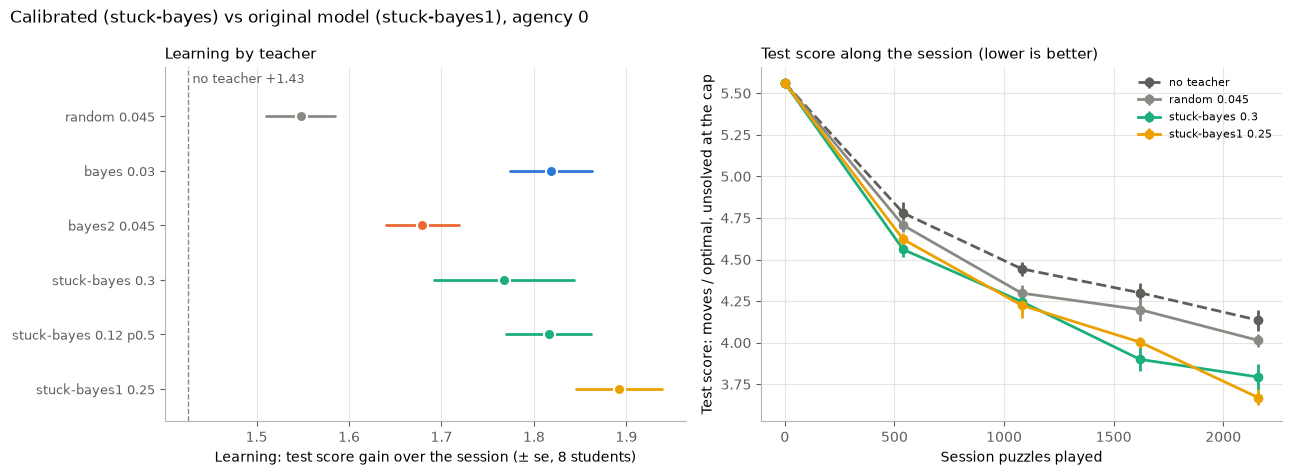

In [5]:
COLORS = {"random:0.045": "#8a8a85", "bayes:0.03": "#2a78d6", "bayes2:0.045": "#eb6834",
          "stuck-bayes:0.3": "#1baf7a", "stuck-bayes:0.12,patience=0.5": "#1baf7a", "stuck-bayes1:0.25": "#eda100"}


def calibration_figure(specs, curves, path):
    """Left: learning ± se per teacher, no teacher as the dashed line. Right: the test score along the session for
    `curves` (lower is better). Saved to `path`."""
    none = entry(NONE_RUN, "none")
    base = np.mean(learning(none))
    rows = [(se.teacher_name(s), *te.mean_se(learning(e)), COLORS[s]) for s in specs
            if (e := entry(RUN, s)) is not None]
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 4.8), width_ratios=[1, 1])
    y = np.arange(len(rows))[::-1]
    for (name, m, s, c), yy in zip(rows, y):
        ax.plot([m - s, m + s], [yy, yy], color=c, lw=2, solid_capstyle="round")
        ax.plot(m, yy, "o", ms=8, color=c, mec="white", mew=1.5)
    ax.axvline(base, color="#8a8a85", lw=1, ls="--", zorder=0)
    ax.text(base, y[0] + 0.55, f" no teacher {base:+.2f}", color="#5f5e5a", fontsize=9, va="bottom")
    ax.set_yticks(y, [r[0] for r in rows], fontsize=9)
    ax.set_ylim(-0.6, len(rows) - 0.1)
    ax.set_xlabel("Learning: test score gain over the session (± se, 8 students)")
    ax.set_title("Learning by teacher", fontsize=11, loc="left")

    for spec in curves:
        e = entry(NONE_RUN, spec) if spec == "none" else entry(RUN, spec)
        if e is None:
            continue
        points = curve(e)
        c = "#5f5e5a" if spec == "none" else COLORS[spec]
        ax2.errorbar([n for n, _ in points], [m for _, (m, _) in points], yerr=[s for _, (_, s) in points],
                     marker="o", ms=6, lw=2, capsize=0, color=c, ls="--" if spec == "none" else "-",
                     label="no teacher" if spec == "none" else se.teacher_name(spec))
    ax2.set_xlabel("Session puzzles played")
    ax2.set_ylabel("Test score: moves / optimal, unsolved at the cap")
    ax2.set_title("Test score along the session (lower is better)", fontsize=11, loc="left")
    ax2.legend(fontsize=8, frameon=False)
    for a in (ax, ax2):
        a.grid(axis="x" if a is ax else "both", color="#e6e5e0", lw=0.8)
        a.set_axisbelow(True)
        for side in ("top", "right"):
            a.spines[side].set_visible(False)
        for side in ("left", "bottom"):
            a.spines[side].set_color("#b5b4ad")
        a.tick_params(colors="#5f5e5a")
    fig.suptitle("Calibrated (stuck-bayes) vs original model (stuck-bayes1), agency 0", x=0.01, ha="left", fontsize=12)
    plt.tight_layout()
    os.makedirs(os.path.dirname(path), exist_ok=True)
    plt.savefig(path, dpi=150)
    plt.show()


calibration_figure(REFERENCE + CALIBRATION, ["none", "random:0.045", "stuck-bayes:0.3"] + CALIBRATION,
                   os.path.join(FIGURES, "stuck_bayes_calibration.png"))

### Result: the original model is at least as good (2026-11-08, agency 0, 8 students, on the PC)

| teacher | shown | solved | helped puzzles | own moves on helped | learning | vs stuck-bayes 0.3 | vs stuck-bayes 0.12 p0.5 | vs bayes 0.03 | vs random 4.5% |
|---|---|---|---|---|---|---|---|---|---|
| stuck-bayes 0.3 | 4.5% | 0.85 | 22% | 121 | +1.77 ± 0.08 | - | +0.05 ± 0.07 | +0.05 ± 0.06 | −0.22 ± 0.10 (5/8) |
| stuck-bayes 0.12 p0.5 | 3.6% | 0.82 | 18% | 144 | +1.82 ± 0.05 | −0.05 ± 0.07 | - | +0.00 ± 0.04 | −0.27 ± 0.07 (8/8) |
| **stuck-bayes1 0.25** | 3.3% | 0.84 | 18% | 151 | **+1.89 ± 0.05** | −0.12 ± 0.09 (4/8) | −0.08 ± 0.04 (5/8) | −0.07 ± 0.06 (5/8) | **−0.34 ± 0.05 (8/8)** |

- **Highest learning of any teacher so far** (+1.89), and the clearest win over random 4.5% (8/8 students).
- **Not matched on spend.** The mini test put it at 4.4%; over the full session it showed 3.3%, falling from 3.6% in
  the first quarter to 3.0% in the last (stuck-bayes 0.3: 4.8% to 4.0%). The original model is more optimistic
  (it gave the student a 0.82 chance of solving alone at the start of a puzzle, the calibrated one 0.77), so it steps
  in later (151 of the student's own moves on helped puzzles, against 121) and on fewer puzzles. The same pattern as
  bayes against bayes2.
- **Against its nearest match on spend,** stuck-bayes 0.12 p0.5 (3.6%, calibrated, earlier gate): −0.08 ± 0.04, 5/8
  students. Suggestive, not conclusive.
- **The lead rests on the last test.** Along the session the two curves cross: stuck-bayes 0.3 is ahead at 1,620
  puzzles, stuck-bayes1 only at the end (2,160). One test point carries a lot of test noise.
- **Every length bin** points the same way (end score, stuck-bayes1 − stuck-bayes 0.3: −0.10, −0.10, −0.15, −0.16
  from the shortest bin to the longest), each within its standard error.

**So the calibration isn't needed** - nothing here favours the calibrated model, and the simpler original one (one
term per distance to the goal instead of two sets) did at least as well. Whether it is *better*, or only spent less,
can't be told from one run: the three best teachers (stuck-bayes1 0.25, stuck-bayes 0.12 p0.5, bayes 0.03) all
show 3.0-3.6% and step in late. That points the help sweep **downward**: theta values for both models that span
about 2-6% spend, so each model's peak is found rather than assumed near 4.5%.

## The help sweep: each model's best amount of help

At agency 0 help has a built-in cost, so learning rises and then falls with the amount shown (random: +1.49 at 3%,
+1.55 at 4.5%, +1.63 at 10%, +1.32 at 30%, +0.00 at 100%). The fair comparison is each teacher at its own best
amount, not at one shared spend. So both models get the same theta grid at patience 1, and learning is plotted
against the spend each run actually reached:

| theta | stuck-bayes (calibrated) | stuck-bayes1 (original) |
|---|---|---|
| 0.1 | new | new |
| 0.25 / 0.3 | saved (0.3: 4.5%) | saved (0.25: 3.3%) |
| 0.5 | new | new |
| 0.75 | new | new |

Spend can't be aimed in advance at the low end. In the mini test (2 students x 80 puzzles) stuck-bayes showed 3.9%,
4.9% and 4.5% at theta 0.1, 0.2 and 0.3 - noise, and a feedback loop: less help, fewer solves, more stuck students,
more help. Over a full session spend also drifts below the mini test's (stuck-bayes1 0.25: 4.4% mini, 3.3% full).
Hence a wide grid, read off the spend reached. 6 teacher runs, about 2.5 hours on the PC; the queue alternates the
models, so a partial sweep is still balanced.

In [6]:
SWEEP_THETAS = [0.1, 0.5, 0.75]
SWEEP = [f"{kind}:{theta:g}" for theta in SWEEP_THETAS for kind in ("stuck-bayes1", "stuck-bayes")]
launch("stuck_bayes_sweep", SWEEP)

stuck_bayes_sweep: all 6 teacher runs are saved, nothing to play


In [7]:
watch("stuck_bayes_sweep")

stuck_bayes_sweep: 100%|██████████| , finished: 6.0/6 teacher runs in 2h22m


### Sweep results

Each model's curve: learning (± se, 8 students) against the share of moves shown, with random's curve and bayes 0.03
for reference. The table pairs each run with stuck-bayes 0.3 and with the other model's run at the same theta.

,teacher,shown,solved as played,learning,vs stuck-bayes 0.3,"vs other model, same theta"
0,stuck-bayes 0.1,0.032,0.803,+1.664 ± 0.033,+0.103 ± 0.090 (3/8),stuck-bayes1 0.1: +0.118 ± 0.079 (3/8)
1,stuck-bayes 0.3,0.045,0.851,+1.768 ± 0.076,,stuck-bayes1 0.25: +0.124 ± 0.088 (4/8)
2,stuck-bayes 0.5,0.057,0.881,+1.841 ± 0.055,-0.074 ± 0.097 (3/8),stuck-bayes1 0.5: -0.008 ± 0.062 (4/8)
3,stuck-bayes 0.75,0.078,0.914,+1.748 ± 0.057,+0.020 ± 0.092 (4/8),stuck-bayes1 0.75: +0.026 ± 0.083 (2/8)
4,stuck-bayes1 0.1,0.027,0.804,+1.783 ± 0.057,-0.015 ± 0.050 (4/8),stuck-bayes 0.1: -0.118 ± 0.079 (5/8)
5,stuck-bayes1 0.25,0.033,0.836,+1.892 ± 0.047,-0.124 ± 0.088 (4/8),stuck-bayes 0.3: -0.124 ± 0.088 (4/8)
6,stuck-bayes1 0.5,0.047,0.873,+1.833 ± 0.040,-0.066 ± 0.100 (5/8),stuck-bayes 0.5: +0.008 ± 0.062 (4/8)
7,stuck-bayes1 0.75,0.067,0.903,+1.774 ± 0.038,-0.007 ± 0.071 (3/8),stuck-bayes 0.75: -0.026 ± 0.083 (6/8)


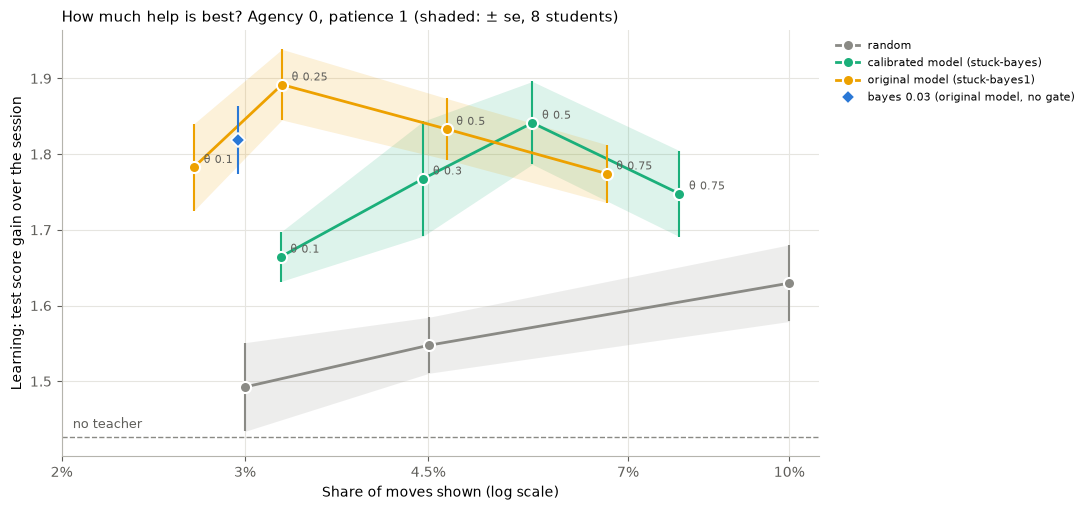

In [8]:
MODELS = {"stuck-bayes": ("calibrated model (stuck-bayes)", "#1baf7a"),
          "stuck-bayes1": ("original model (stuck-bayes1)", "#eda100")}
SWEEP_SPECS = {"stuck-bayes": ["stuck-bayes:0.1", "stuck-bayes:0.3", "stuck-bayes:0.5", "stuck-bayes:0.75"],
               "stuck-bayes1": ["stuck-bayes1:0.1", "stuck-bayes1:0.25", "stuck-bayes1:0.5", "stuck-bayes1:0.75"]}
RANDOM = ["random:0.03", "random:0.045", "random:0.1"]


def spend(e):
    records = [x for record in e["sessions"].values() for x in record]
    return sum(x["taught"] for x in records) / sum(x["moves"] for x in records)


def sweep_table():
    rows = []
    for kind, specs in SWEEP_SPECS.items():
        other = "stuck-bayes" if kind == "stuck-bayes1" else "stuck-bayes1"
        for spec, twin in zip(specs, SWEEP_SPECS[other]):
            e = entry(RUN, spec)
            if e is None:
                continue
            m, s = te.mean_se(learning(e))
            base, partner = entry(RUN, "stuck-bayes:0.3"), entry(RUN, twin)
            rows.append({"teacher": se.teacher_name(spec), "shown": spend(e),
                         "solved as played": np.mean([x["solved"] for r in e["sessions"].values() for x in r]),
                         "learning": f"{m:+.3f} ± {s:.3f}",
                         "vs stuck-bayes 0.3": paired(e, base) if spec != "stuck-bayes:0.3" else "",
                         "vs other model, same theta": f"{se.teacher_name(twin)}: {paired(e, partner)}"
                         if partner is not None else ""})
    return pd.DataFrame(rows).round(3)


def sweep_figure(path):
    """Learning against spend: one line per model (labelled with theta), random's curve, bayes 0.03, no teacher."""
    fig, ax = plt.subplots(figsize=(11, 5.2))
    none = entry(NONE_RUN, "none")
    base = np.mean(learning(none))
    ax.axhline(base, color="#8a8a85", lw=1, ls="--", zorder=0)
    ax.text(0.0205, base + 0.008, "no teacher", color="#5f5e5a", fontsize=9, va="bottom")
    lines = [("random", RANDOM, "#8a8a85")] + [(label, SWEEP_SPECS[k], c) for k, (label, c) in MODELS.items()]
    for label, specs, c in lines:
        pts = [(spend(e), *te.mean_se(learning(e)), spec) for spec in specs if (e := entry(RUN, spec)) is not None]
        if not pts:
            continue
        pts.sort()
        x, m, s = (np.array([p[i] for p in pts]) for i in range(3))
        ax.fill_between(x, m - s, m + s, color=c, alpha=0.15, lw=0)
        ax.errorbar(x, m, yerr=s, fmt="none", ecolor=c, elinewidth=1.5, capsize=0)
        ax.plot(x, m, "-o", color=c, lw=2, ms=8, mec="white", mew=1.5, label=label)
        if label != "random":
            for xx, mm, spec in zip(x, m, [p[3] for p in pts]):
                ax.annotate(f"θ {spec.split(':')[1]}", (xx, mm), xytext=(7, 3), textcoords="offset points",
                            ha="left", fontsize=8, color="#5f5e5a")
    b = entry(RUN, "bayes:0.03")
    if b is not None:
        m, s = te.mean_se(learning(b))
        ax.errorbar(spend(b), m, yerr=s, fmt="D", ms=7, color="#2a78d6", mec="white", mew=1.2, capsize=0,
                    label="bayes 0.03 (original model, no gate)")
    ax.set_xscale("log")
    ax.set_xticks([0.02, 0.03, 0.045, 0.07, 0.1], ["2%", "3%", "4.5%", "7%", "10%"])
    ax.minorticks_off()
    ax.set_xlabel("Share of moves shown (log scale)")
    ax.set_ylabel("Learning: test score gain over the session")
    ax.set_title("How much help is best? Agency 0, patience 1 (shaded: ± se, 8 students)", fontsize=11, loc="left")
    ax.legend(fontsize=8, frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
    ax.grid(color="#e6e5e0", lw=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color("#b5b4ad")
    ax.tick_params(colors="#5f5e5a")
    plt.tight_layout()
    os.makedirs(os.path.dirname(path), exist_ok=True)
    plt.savefig(path, dpi=150)
    plt.show()


display(sweep_table())
sweep_figure(os.path.join(FIGURES, "stuck_bayes_sweep.png"))

### Result: one peak per model, about the same height; the original model needs less help to reach it

| theta | calibrated (stuck-bayes): shown, learning | original (stuck-bayes1): shown, learning |
|---|---|---|
| 0.1 | 3.2%, +1.66 ± 0.03 | 2.7%, +1.78 ± 0.06 |
| 0.25 / 0.3 | 4.5%, +1.77 ± 0.08 | **3.3%, +1.89 ± 0.05** |
| 0.5 | **5.7%, +1.84 ± 0.06** | 4.7%, +1.83 ± 0.04 |
| 0.75 | 7.8%, +1.75 ± 0.06 | 6.7%, +1.77 ± 0.04 |

- **Both curves rise and fall**, as the assistance dilemma predicts, and both stay well above random (+1.49 to +1.63
  at 3-10%) everywhere they were tried.
- **The original model peaks at theta 0.25 (3.3% shown).** Paired with that peak, its own neighbours learn less:
  theta 0.1 by 0.11 ± 0.05 (6/8 students), 0.5 by 0.06 ± 0.06 (6/8), and 0.75 by 0.12 ± 0.07 (6/8). The peak is
  real but broad. Anywhere from about 3% to 5% is within about one standard error of it.
- **The calibrated model peaks at theta 0.5 (5.7% shown)**, 0.05 ± 0.04 below the original's peak (4/8). The two
  peaks are the same height within noise, but the original model gets there with about 40% less help shown.
- **At the same theta the models pick different amounts of help.** The original model's solve-chance estimate sits
  higher, so it shows less. Where their spends overlap (4.5-7%) the curves agree. The original model also extends
  the curve down to 2.7-3.3%, where the calibrated model never goes at these thetas. That low region is where the
  best run so far, stuck-bayes1 0.25, lies.
- **References at the peak:** bayes 0.03 (the original model with no gate, 3%) is 0.07 ± 0.06 below it (5/8).
  The model-free hint 5 p2 is 0.20 ± 0.05 below (8/8), and hint-bayes 0.25 is 0.19 ± 0.05 below (7/8).

**Baseline for the ablations: stuck-bayes1, theta 0.25, patience 1.** Each ablation removes one part of it. Since
removing a part shifts how much help a given theta buys, each one gets two thetas, aimed at the baseline's peak
(about 3.3% shown) and at its theta 0.5 point (about 4.7%). It is then read against the baseline curve: its best
run against the baseline's best, and each run against the baseline at the same spend.

## Ablations: which parts of stuck-bayes1 does it need?

The baseline is stuck-bayes1 at theta 0.25, patience 1: 3.3% shown, +1.89 learning, the best teacher so far. It has
an original-model (Bayesian) picture of the student under a gate. Each ablation removes one part, using a switch on
the teacher (`scripts/teach.py`, StuckGate):

| switch | part removed | what is left |
|---|---|---|
| `patience=0` | the gate | the solve-chance rule alone, from the first move |
| `update=0` | updating this puzzle's difficulty from the student's moves on it | the plan averages over the prior; being stuck is still seen by the gate |
| `refit=100` | following the student's learning | the model of the student (skill per distance, level, tau, mistakes, persistence) learns from the first 100 of 2,160 puzzles, then stays fixed |
| `giveup=0` | the persistence model | no chance of giving up in the plan: only the move cap ends a puzzle |
| `backward=0` | the direction of mistakes | every mistake is sideways: the plan never has the student slide back |

Removing a part changes how much help a given theta buys, so each ablation's thetas came from the mini test (2
students x 80 puzzles). They were aimed at the baseline's mini-test spend at theta 0.25 (4.4%, which is 3.3% in a
full session) and at theta 0.5 (6.4%, which is 4.7%). Mini-test spend at theta 0.25, against the baseline's 4.4%:

| ablation | 0.25 | 0.45 | 0.5 | 0.7 | 0.85 | chosen thetas |
|---|---|---|---|---|---|---|
| no gate | 4.8% | 6.4% | | | | 0.2, 0.45 |
| no update | 2.8% | 4.0% | 4.8% | 5.6% | 10.3% | 0.5, 0.75 |
| frozen (refit 20 as proxy) | 4.8% | | | | | 0.25, 0.5 (as the baseline) |
| no give-up | 3.6% | 4.4% | | 5.8% (0.6) | | 0.45, 0.7 |
| no backward | 2.6% | 2.2% | | 3.0% | 4.9% (12.2% at 0.95) | 0.82, 0.88 |

- With no backward mistakes, the model thinks the student almost always gets there, until the move cap is close. So
  spend hardly moves until theta is above 0.8, and then it climbs steeply.
- Without the gate, the same theta buys about the same help. The model rarely gives the student under 0.25 before
  it is stuck anyway.
- The mini test can't see `refit=100` (it ends at 80 puzzles). `refit=20` shows a bit more help, so the full runs
  use the baseline's thetas.

10 runs, about 22 minutes each (about 3.7 hours). The queue plays every ablation's first theta before any second
one, so a partial queue still covers all five parts.

In [ ]:
ABLATIONS = {  # label: (switch, [thetas])
    "no gate": ("patience=0", [0.2, 0.45]),
    "no within-puzzle update": ("update=0", [0.5, 0.75]),
    "frozen after 100 puzzles": ("refit=100", [0.25, 0.5]),
    "no give-up in the plan": ("giveup=0", [0.45, 0.7]),
    "mistakes all sideways": ("backward=0", [0.82, 0.88]),
}
ABLATION_SPECS = {label: [f"stuck-bayes1:{t:g},{switch}" for t in thetas] for label, (switch, thetas) in ABLATIONS.items()}
launch("stuck_bayes_ablations", [specs[i] for i in range(2) for specs in ABLATION_SPECS.values()])

In [ ]:
watch("stuck_bayes_ablations")

### Ablation results

The table and figure compare each ablation with the baseline curve (stuck-bayes1 at theta 0.1 / 0.25 / 0.5 / 0.75).
"vs baseline peak" pairs each run with stuck-bayes1 0.25. "vs baseline, nearest spend" pairs it with the baseline
run whose spend is closest. Both are learning differences: above 0 means the ablation learned more. The last panel
puts each ablation's best run against the baseline's best. With 8 students, a difference within about ±0.1 can't be
told apart from no difference.

In [ ]:
BASELINE = "stuck-bayes1:0.25"
BASELINE_CURVE = ["stuck-bayes1:0.1", "stuck-bayes1:0.25", "stuck-bayes1:0.5", "stuck-bayes1:0.75"]


def learning_gain(e, base):
    """Learning minus `base`'s, student by student (all start from the same network): (mean, se, k better, n)."""
    a, b = dict(zip(final(e), learning(e))), dict(zip(final(base), learning(base)))
    d = [a[s] - b[s] for s in a if s in b]
    return (*te.mean_se(d), sum(x > 0 for x in d), len(d))


def gain_text(e, base):
    m, s, k, n = learning_gain(e, base)
    return f"{m:+.3f} ± {s:.3f} ({k}/{n})"


def ablation_table():
    curve_runs = [(spend(b), spec, b) for spec in BASELINE_CURVE if (b := entry(RUN, spec)) is not None]
    peak = entry(RUN, BASELINE)
    rows = []
    for label, specs in {"baseline": BASELINE_CURVE, **ABLATION_SPECS}.items():
        for spec in specs:
            e = entry(RUN, spec)
            if e is None:
                print(f"{se.teacher_name(spec)}: not saved yet")
                continue
            m, s = te.mean_se(learning(e))
            near = min(curve_runs, key=lambda c: abs(np.log(c[0] / spend(e))))
            rows.append({"ablation": label, "teacher": se.teacher_name(spec), "shown": spend(e),
                         "solved as played": np.mean([x["solved"] for r in e["sessions"].values() for x in r]),
                         "learning": f"{m:+.3f} ± {s:.3f}",
                         "vs baseline peak": gain_text(e, peak) if spec != BASELINE else "",
                         "vs baseline, nearest spend": f"{se.teacher_name(near[1])}: {gain_text(e, near[2])}"
                         if label != "baseline" else ""})
    return pd.DataFrame(rows).round(3)


def _style(ax):
    ax.grid(color="#e6e5e0", lw=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color("#b5b4ad")
    ax.tick_params(colors="#5f5e5a", labelsize=8)


def _points(specs):
    pts = sorted((spend(e), *te.mean_se(learning(e)), spec) for spec in specs if (e := entry(RUN, spec)) is not None)
    return [np.array([p[i] for p in pts]) for i in range(3)] + [[p[3] for p in pts]]


def _theta(spec):
    return spec.split(":")[1].split(",")[0]


def ablation_figure(path):
    """One panel per ablation (its runs against the baseline curve), and a last panel: each ablation's best run
    minus the baseline's best, paired by student."""
    n = len(ABLATION_SPECS) + 1  # a panel per ablation, and the summary
    rows_ = -(-n // 3)
    fig, axes = plt.subplots(rows_, 3, figsize=(13, 3.8 * rows_), squeeze=False)
    panels = list(axes.flat)
    bx, bm, bs, _ = _points(BASELINE_CURVE)
    for ax, (label, specs) in zip(panels, ABLATION_SPECS.items()):
        ax.fill_between(bx, bm - bs, bm + bs, color="#8a8a85", alpha=0.15, lw=0)
        ax.plot(bx, bm, "-o", color="#8a8a85", lw=2, ms=6, mec="white", mew=1.2, label="baseline (stuck-bayes1)")
        x, m, s, sp = _points(specs)
        if len(x):
            ax.errorbar(x, m, yerr=s, fmt="-o", color="#2a78d6", lw=2, ms=8, mec="white", mew=1.5, capsize=0,
                        label="ablated")
            for xx, mm, spec in zip(x, m, sp):
                ax.annotate(f"θ {_theta(spec)}", (xx, mm), xytext=(7, 3), textcoords="offset points", fontsize=8,
                            color="#5f5e5a")
        ax.set_xscale("log")
        ax.set_xticks([0.02, 0.03, 0.045, 0.07, 0.1], ["2%", "3%", "4.5%", "7%", "10%"])
        ax.minorticks_off()
        ax.set_xlim(0.02, 0.11)
        ax.set_ylim(1.45, 2.05)
        ax.set_title(label, fontsize=10, loc="left")
        _style(ax)
    panels[0].legend(fontsize=8, frameon=False, loc="lower right")
    for i, ax in enumerate(panels[:n - 1]):
        if i + 3 >= n - 1:  # no ablation panel below it
            ax.set_xlabel("Share of moves shown (log scale)", fontsize=9)
        if i % 3 == 0:
            ax.set_ylabel("Learning (test score gain)", fontsize=9)
    for ax in panels[n:]:
        ax.axis("off")

    ax = panels[n - 1]
    peak, rows = entry(RUN, BASELINE), []
    for label, specs in ABLATION_SPECS.items():
        saved = [(np.mean(learning(e)), spec, e) for spec in specs if (e := entry(RUN, spec)) is not None]
        if saved:
            _, spec, e = max(saved, key=lambda t: t[0])
            rows.append((label, spec, *learning_gain(e, peak)))
    for i, (label, spec, m, s, k, n) in enumerate(rows):
        ax.errorbar(m, i, xerr=s, fmt="o", color="#2a78d6", ms=8, mec="white", mew=1.5, capsize=0)
        ax.annotate(f"θ {_theta(spec)}, {k}/{n} better", (m, i), xytext=(0, 8), textcoords="offset points",
                    ha="center", fontsize=8, color="#5f5e5a")
    ax.axvline(0, color="#8a8a85", lw=1, ls="--")
    ax.axvspan(-0.1, 0.1, color="#8a8a85", alpha=0.08, lw=0)
    ax.set_yticks(range(len(rows)), [r[0] for r in rows], fontsize=8)
    ax.set_ylim(-0.6, max(len(rows), 1) - 0.4)
    ax.invert_yaxis()
    ax.set_xlabel("Best run's learning minus baseline peak's (± se)", fontsize=9)
    ax.set_title("Each ablation at its best", fontsize=10, loc="left")
    _style(ax)
    fig.suptitle("Ablating stuck-bayes1 (agency 0, 8 students; shaded: baseline ± se; grey band: ±0.1)",
                 fontsize=11, x=0.01, ha="left")
    plt.tight_layout()
    os.makedirs(os.path.dirname(path), exist_ok=True)
    plt.savefig(path, dpi=150)
    plt.show()


display(ablation_table())
ablation_figure(os.path.join(FIGURES, "stuck_bayes_ablations.png"))

### Result: the gate and the give-up model can go; backward mistakes stay; the rest is unclear at 8 students

Each ablation's learning minus the baseline's, paired by student (above 0: the ablation learned more):

| ablation | run (shown) | vs baseline peak (θ 0.25, 3.3%) | vs baseline at nearest spend |
|---|---|---|---|
| no gate | θ 0.2 (3.0%) | +0.01 ± 0.04 (3/8) | same |
| | θ 0.45 (4.6%) | **+0.02 ± 0.05 (5/8)** | +0.08 ± 0.07 vs θ 0.5 |
| no give-up in the plan | θ 0.45 (3.7%) | −0.07 ± 0.07 (3/8) | same |
| | θ 0.7 (4.9%) | **+0.01 ± 0.07 (4/8)** | +0.07 ± 0.09 vs θ 0.5 |
| frozen after 100 puzzles | θ 0.25 (3.0%) | −0.09 ± 0.06 (3/8) | same |
| | θ 0.5 (4.2%) | **−0.04 ± 0.04 (2/8)** | +0.02 ± 0.06 vs θ 0.5 |
| no within-puzzle update | θ 0.5 (2.2%) | −0.14 ± 0.03 (1/8) | −0.03 ± 0.06 vs θ 0.1 |
| | θ 0.75 (5.5%) | **−0.08 ± 0.06 (2/8)** | −0.02 ± 0.07 vs θ 0.5 |
| mistakes all sideways | θ 0.82 (3.2%) | −0.15 ± 0.07 (2/8) | same |
| | θ 0.88 (5.0%) | **−0.09 ± 0.07 (2/8)** | −0.03 ± 0.09 vs θ 0.5 |

- **No gate: not needed.** Both runs match the baseline's peak. At 4.6% the curve without the gate is flatter than
  the baseline's (+1.91 against +1.83 at θ 0.5). A likely reason: early in a puzzle the solve chance is rarely
  below theta until the student's own moves have lowered it, so the rule holds back on its own and patience adds
  nothing.
- **No give-up in the plan: not needed.** θ 0.7 (4.9%) ties the peak. With only the move cap ending a puzzle, the
  model is more optimistic, so it takes a higher theta for the same help, and a higher theta is all it needs.
- **Mistakes all sideways: a loss.** At the baseline's own spend (3.2%) it learns 0.15 ± 0.07 less (6/8 students
  worse). It is the clearest loss here. Without backward mistakes the model sees no difference between a student
  who slides back and one who stalls, so its solve chance stays near 1 until the move cap is close (in the mini test its
  spend barely moved until theta passed 0.8).
- **Frozen after 100 puzzles: probably a small loss.** At its best it is 0.04 ± 0.04 below (6/8 worse). At the same
  spend it is between −0.09 and +0.02. Following the student's learning seems worth a little, but 8 students can't
  pin that down.
- **No within-puzzle update: unclear.** Its spend landed at 2.2% and 5.5%, missing the peak region (3-4%). Against
  the baseline at the nearest spend it is level (−0.02 to −0.03). Against the peak it is 0.08 below at best. It
  needs a run near 3.3% (theta about 0.6).

**Caveat:** the baseline peak is the best of four runs, so part of its lead over any single run is luck: pick the
best of four noisy runs and you pick some noise. The "nearest spend" column avoids that, and there only the
sideways-mistakes run at matched spend loses clearly.

**So far the most parsimonious candidate is the original model's solve-chance rule with no gate and no give-up
model,** keeping backward mistakes. Following the student's learning and within-puzzle updating stay until tested
better. Next: run that combination (removals can interact) and no-update near 3.3%. Then confirm the candidate
against the baseline with more students (16-24), since a difference under about 0.1 can't be resolved at 8.

## Follow-up: the combined candidate, and no-update at the peak

The single ablations left two gaps:

1. **The combination has never been run.** Dropping the gate is fine, and dropping the give-up model is fine, each on
   its own. Removals can interact, though: without the gate, only the solve-chance estimate holds help back early in a
   puzzle, and the give-up model feeds that estimate. So the candidate, stuck-bayes1 with `patience=0, giveup=0`, gets
   its own runs.
2. **No-update's spend missed the peak region.** It landed at 2.2% and 5.5%, against targets of 3.3% and 4.7%.
   Interpolating its two runs on a log scale puts 3.3% at about theta 0.6, so it gets theta 0.6 and 0.65.

Mini-test spend for the combination (2 students x 80 puzzles; noisy) was 3.9% at theta 0.35, 4.7% at 0.5, 7.8% at
0.65 and 7.1% at 0.8. Without the gate alone, mini spend runs about 1.4 times full-session spend, so theta 0.45 and 0.6
aim at about 3.3% and 4.7%. 4 runs, about 1.5 hours.

In [ ]:
ABLATION_SPECS["no gate + no give-up"] = [f"stuck-bayes1:{t:g},patience=0,giveup=0" for t in (0.45, 0.6)]
NO_UPDATE_FILL = ["stuck-bayes1:0.6,update=0", "stuck-bayes1:0.65,update=0"]
ABLATION_SPECS["no within-puzzle update"] += NO_UPDATE_FILL
launch("stuck_bayes_ablations2", ["stuck-bayes1:0.45,patience=0,giveup=0", NO_UPDATE_FILL[0],
                                  "stuck-bayes1:0.6,patience=0,giveup=0", NO_UPDATE_FILL[1]])

In [ ]:
watch("stuck_bayes_ablations2")

In [ ]:
display(ablation_table())
ablation_figure(os.path.join(FIGURES, "stuck_bayes_ablations.png"))